<a href="https://colab.research.google.com/github/ZiyuCao421/26-CP5046-SIN-CAM-TR3-ICT-Project-1-Analysis-and-Design/blob/main/CP5408_A1_DJI_Risk_Analysis_Completed_v2.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# CP5408 A1: Quantitative Cyber Risk Analysis — DJI Commercial Drone Delivery

This notebook supports the quantitative risk assessment for DJI's commercial drone delivery ecosystem, focusing on the FlyCart 30 and the DeliveryHub / DJI unified-account environment. It calculates the financial exposure of three priority scenarios selected from the Practical 2 risk register: **R1 (GNSS spoofing/navigation disruption), R3 (privileged account compromise), and R7 (credential stuffing/account takeover)**.

**Scope clarification for R3:** the scenario is mapped to privileged access involving the DeliveryHub / DJI unified-account environment. The numerical inputs are retained from the original coursework scenario model; they are **not** product-specific measured incident data and do not establish that DeliveryHub lacks MFA. Phishing-resistant MFA is evaluated as a proposed treatment.

**Data limitation:** ARO, SLE, annual control costs, and treatment-effect percentages are scenario estimates for this assessment, not DJI internal incident frequencies, actual losses, or audited costs. The Low / Most Likely / High sensitivity ranges are scenario tests, not statistical confidence intervals.

**How to use:** run all cells from top to bottom. The notebook validates inputs, calculates ALE and residual risk, creates report-ready figures and CSV outputs, and tests sensitivity to ARO/SLE assumptions. The optional illustrative incident-trend data from the original practical has been excluded from this A1 analysis so it cannot be mistaken for DJI observations.

## 0. Setup

Run this cell first. No package installation is required in standard Google Colab or a typical Anaconda/Jupyter environment.

The code below defines the shared five-point risk scale, formatting helpers, and the figure-saving function.

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from matplotlib.ticker import FuncFormatter
from matplotlib.colors import ListedColormap, BoundaryNorm
from matplotlib.patches import Patch

pd.set_option('display.float_format', '{:,.2f}'.format)
pd.set_option('display.max_columns', 30)
pd.set_option('display.width', 200)

SAVE_FIGURES = True
dollars = FuncFormatter(lambda v, _: f'${v:,.0f}')

# Same five-point scale as Practical 2
LIKELIHOOD_LABELS = ['1 Rare', '2 Unlikely', '3 Possible', '4 Likely', '5 Almost certain']
IMPACT_LABELS = ['1 Trivial', '2 Minor', '3 Moderate', '4 Serious', '5 Severe']

def finish(fig_name):
    # Tidy the current figure, optionally save it as a PNG, then display it.
    plt.tight_layout()
    if SAVE_FIGURES:
        plt.savefig(f'{fig_name}.png', dpi=200, bbox_inches='tight')
    plt.show()

## 1. Input table

The selected scenarios are R1, R3, and R7 from Practical 2. Their qualitative likelihood and impact ratings are retained from the original risk register. Quantitative inputs are scenario assumptions.

R3 is labelled as **privileged account compromise** to align the final report's system boundary with DeliveryHub / DJI unified-account access. This is a scenario mapping, not a claim that a specific DeliveryHub vulnerability or MFA deficiency has been verified.

Control costs are treated as **annual total cost of ownership** for comparison with annual ALE. If a cost estimate represents a one-off implementation cost, it must be annualised before interpreting net benefit or BCR.

In [2]:
risk_inputs = pd.DataFrame([
    {
        'Risk_ID': 'R3',
        'Risk_Name': 'Privileged account compromise',
        'ARO': 0.5,
        'SLE': 350000,
        'Likelihood_1_to_5': 4,
        'Impact_1_to_5': 4,
        'Treatment_Option': 'Reduce likelihood',
        'Control_Name': 'Phishing-resistant MFA',
        'Control_Cost': 80000,
        'Likelihood_Reduction_pct': 60,
        'Impact_Reduction_pct': 0,
    },
    {
        'Risk_ID': 'R7',
        'Risk_Name': 'Credential stuffing takeover',
        'ARO': 2.0,
        'SLE': 45000,
        'Likelihood_1_to_5': 4,
        'Impact_1_to_5': 4,
        'Treatment_Option': 'Reduce likelihood',
        'Control_Name': 'Credential-stuffing detection + MFA',
        'Control_Cost': 50000,
        'Likelihood_Reduction_pct': 70,
        'Impact_Reduction_pct': 0,
    },
    {
        'Risk_ID': 'R1',
        'Risk_Name': 'GPS spoofing drone crash',
        'ARO': 0.2,
        'SLE': 2000000,
        'Likelihood_1_to_5': 3,
        'Impact_1_to_5': 5,
        'Treatment_Option': 'Reduce impact',
        'Control_Name': 'VIO fallback + return-to-home',
        'Control_Cost': 250000,
        'Likelihood_Reduction_pct': 0,
        'Impact_Reduction_pct': 50,
    },
])

# Display the three base assumptions before calculations begin.
risk_inputs

,Risk_ID,Risk_Name,ARO,SLE,Likelihood_1_to_5,Impact_1_to_5,Treatment_Option,Control_Name,Control_Cost,Likelihood_Reduction_pct,Impact_Reduction_pct
0,R3,Privileged account compromise,0.50,350000,4,4,Reduce likelihood,Phishing-resistant MFA,80000,60,0
1,R7,Credential stuffing takeover,2.00,45000,4,4,Reduce likelihood,Credential-stuffing detection + MFA,50000,70,0
2,R1,GPS spoofing drone crash,0.20,2000000,3,5,Reduce impact,VIO fallback + return-to-home,250000,0,50


## 2. Check the inputs

This cell checks for common input problems. Run it after editing the input table. If it stops with a message, fix the input table and run it again.

In [3]:
required_columns = [
    'Risk_ID', 'Risk_Name', 'ARO', 'SLE', 'Likelihood_1_to_5', 'Impact_1_to_5',
    'Treatment_Option', 'Control_Name', 'Control_Cost',
    'Likelihood_Reduction_pct', 'Impact_Reduction_pct'
]
numeric_columns = ['ARO', 'SLE', 'Likelihood_1_to_5', 'Impact_1_to_5', 'Control_Cost',
                   'Likelihood_Reduction_pct', 'Impact_Reduction_pct']

missing = [col for col in required_columns if col not in risk_inputs.columns]
if missing:
    raise ValueError(f'Missing required columns: {missing}')

not_numeric = [col for col in numeric_columns if not pd.api.types.is_numeric_dtype(risk_inputs[col])]
if not_numeric:
    raise ValueError(f'These columns must contain plain numbers (no quotes, commas or $ signs): {not_numeric}')

duplicates = risk_inputs.loc[risk_inputs['Risk_ID'].duplicated(), 'Risk_ID'].tolist()
if duplicates:
    raise ValueError(f'Each Risk_ID must be unique. Duplicated: {duplicates}')

checks = {
    'ARO must be zero or more': (risk_inputs['ARO'] >= 0).all(),
    'SLE must be zero or more': (risk_inputs['SLE'] >= 0).all(),
    'ARO and SLE must be finite': np.isfinite(risk_inputs[['ARO', 'SLE']].to_numpy()).all(),
    'Control_Cost must be zero or more': (risk_inputs['Control_Cost'] >= 0).all(),
    'Likelihood_1_to_5 must be a whole number from 1 to 5': risk_inputs['Likelihood_1_to_5'].isin([1, 2, 3, 4, 5]).all(),
    'Impact_1_to_5 must be a whole number from 1 to 5': risk_inputs['Impact_1_to_5'].isin([1, 2, 3, 4, 5]).all(),
    'Likelihood_Reduction_pct must be between 0 and 100': risk_inputs['Likelihood_Reduction_pct'].between(0, 100).all(),
    'Impact_Reduction_pct must be between 0 and 100': risk_inputs['Impact_Reduction_pct'].between(0, 100).all(),
}
failed = [message for message, passed in checks.items() if not passed]
if failed:
    raise ValueError('Input check failed: ' + '; '.join(failed))

# Warnings: these do not stop the notebook, but are usually mistakes.
for col in ['Likelihood_Reduction_pct', 'Impact_Reduction_pct']:
    small = risk_inputs[(risk_inputs[col] > 0) & (risk_inputs[col] < 1)]
    for _, row in small.iterrows():
        print(f"WARNING {row['Risk_ID']}: {col} = {row[col]}. Enter 40 for 40 percent, not 0.4.")
for _, row in risk_inputs[risk_inputs['Risk_Name'].str.len() > 40].iterrows():
    print(f"WARNING {row['Risk_ID']}: Risk_Name is long and may be cut off on charts. Aim for under 40 characters.")
for _, row in risk_inputs[risk_inputs['Risk_Name'].str.startswith('Replace with')].iterrows():
    print(f"NOTE {row['Risk_ID']}: still using the placeholder risk name.")

expected_ids = {'R1', 'R3', 'R7'}
if set(risk_inputs['Risk_ID']) != expected_ids:
    raise ValueError(f'Expected exactly the selected risks {sorted(expected_ids)}.')

print('Input checks passed.')

Input checks passed.


## 3. Calculate the risk metrics

This cell calculates all derived values. You do not need to edit it.

| Value | Formula |
|---|---|
| ALE | ARO × SLE |
| Residual ARO | ARO × (1 − likelihood reduction) |
| Residual SLE | SLE × (1 − impact reduction) |
| Residual ALE | Residual ARO × Residual SLE |
| Risk reduction | ALE − Residual ALE |
| Net benefit | Risk reduction − Control cost (this is the security ROI idea from the Week 3 seminar) |
| Benefit-cost ratio | Risk reduction ÷ Control cost |
| Qualitative score | Likelihood × Impact; bands: Extreme 20–25, High 12–19, Medium 6–11, Low 1–5 |

In [4]:
risks = risk_inputs.copy()

risks['ALE'] = risks['ARO'] * risks['SLE']

risks['Residual_ARO'] = risks['ARO'] * (1 - risks['Likelihood_Reduction_pct'] / 100)
risks['Residual_SLE'] = risks['SLE'] * (1 - risks['Impact_Reduction_pct'] / 100)
risks['Residual_ALE'] = risks['Residual_ARO'] * risks['Residual_SLE']

risks['Risk_Reduction'] = risks['ALE'] - risks['Residual_ALE']
risks['Net_Benefit'] = risks['Risk_Reduction'] - risks['Control_Cost']
risks['Benefit_Cost_Ratio'] = np.where(risks['Control_Cost'] > 0,
                                       risks['Risk_Reduction'] / risks['Control_Cost'], np.nan)

risks['Qualitative_Risk_Score'] = risks['Likelihood_1_to_5'] * risks['Impact_1_to_5']

def risk_band(score):
    if score >= 20:
        return 'Extreme'
    if score >= 12:
        return 'High'
    if score >= 6:
        return 'Medium'
    return 'Low'

risks['Qualitative_Risk_Band'] = risks['Qualitative_Risk_Score'].apply(risk_band)
risks['Label'] = risks['Risk_ID'] + ' - ' + risks['Risk_Name']

risks_sorted = risks.sort_values('ALE', ascending=False).reset_index(drop=True)
print(f'Calculated metrics for {len(risks)} risks.')

Calculated metrics for 3 risks.


## 4. Summary tables

These two tables contain the values most relevant to Assignment 1. Both are generated from your input table. They are also saved as `risk_summary.csv`.

In [5]:
before_columns = ['Risk_ID', 'Risk_Name', 'ARO', 'SLE', 'ALE', 'Qualitative_Risk_Score', 'Qualitative_Risk_Band']
risks_sorted[before_columns]

,Risk_ID,Risk_Name,ARO,SLE,ALE,Qualitative_Risk_Score,Qualitative_Risk_Band
0,R1,GPS spoofing drone crash,0.20,2000000,"400,000.00",15,High
1,R3,Privileged account compromise,0.50,350000,"175,000.00",16,High
2,R7,Credential stuffing takeover,2.00,45000,"90,000.00",16,High


In [6]:
after_columns = ['Risk_ID', 'Control_Name', 'Control_Cost', 'Residual_ARO', 'Residual_SLE',
                 'Residual_ALE', 'Risk_Reduction', 'Net_Benefit', 'Benefit_Cost_Ratio']
if SAVE_FIGURES:
    risks_sorted.drop(columns=['Label']).to_csv('risk_summary.csv', index=False)
risks_sorted[after_columns]

,Risk_ID,Control_Name,Control_Cost,Residual_ARO,Residual_SLE,Residual_ALE,Risk_Reduction,Net_Benefit,Benefit_Cost_Ratio
0,R1,VIO fallback + return-to-home,250000,0.20,"1,000,000.00","200,000.00","200,000.00","-50,000.00",0.80
1,R3,Phishing-resistant MFA,80000,0.20,"350,000.00","70,000.00","105,000.00","25,000.00",1.31
2,R7,Credential-stuffing detection + MFA,50000,0.60,"45,000.00","27,000.00","63,000.00","13,000.00",1.26


## 5. Figure 1: ALE ranking

Ranks risks by expected annual loss before treatment.

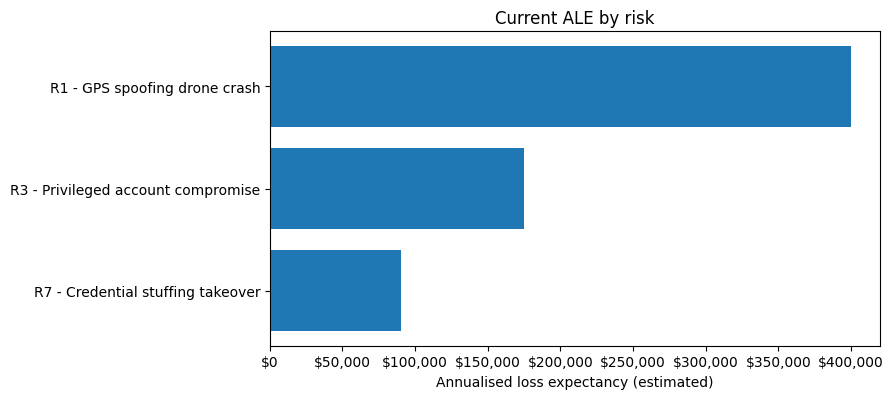

In [7]:
plot_data = risks_sorted.sort_values('ALE')

fig, ax = plt.subplots(figsize=(9, 0.7 * len(plot_data) + 2))
ax.barh(plot_data['Label'], plot_data['ALE'])
ax.xaxis.set_major_formatter(dollars)
ax.set_xlabel('Annualised loss expectancy (estimated)')
ax.set_title('Current ALE by risk')
finish('fig1_ale_ranking')

## 6. Figure 2: Current vs residual ALE

Compares expected annual loss before and after the proposed treatment.

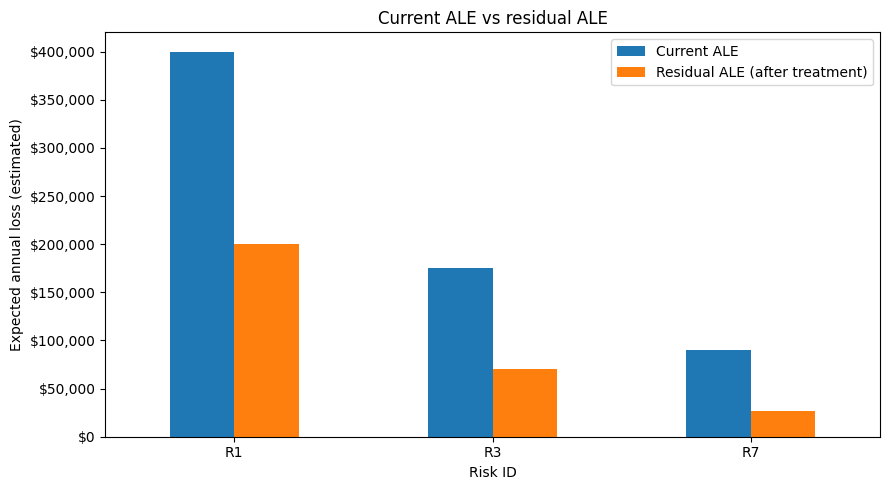

In [8]:
comparison = risks_sorted.set_index('Risk_ID')[['ALE', 'Residual_ALE']]
comparison.columns = ['Current ALE', 'Residual ALE (after treatment)']

ax = comparison.plot(kind='bar', figsize=(9, 5))
ax.yaxis.set_major_formatter(dollars)
ax.set_xlabel('Risk ID')
ax.set_ylabel('Expected annual loss (estimated)')
ax.set_title('Current ALE vs residual ALE')
plt.xticks(rotation=0)
finish('fig2_current_vs_residual')

## 7. Figure 3: Risk reduction compared with control cost

Compares the estimated annual risk reduction with the estimated annual cost of each control. Where the cost bar is taller than the reduction bar, the control costs more than the loss it is expected to avoid.

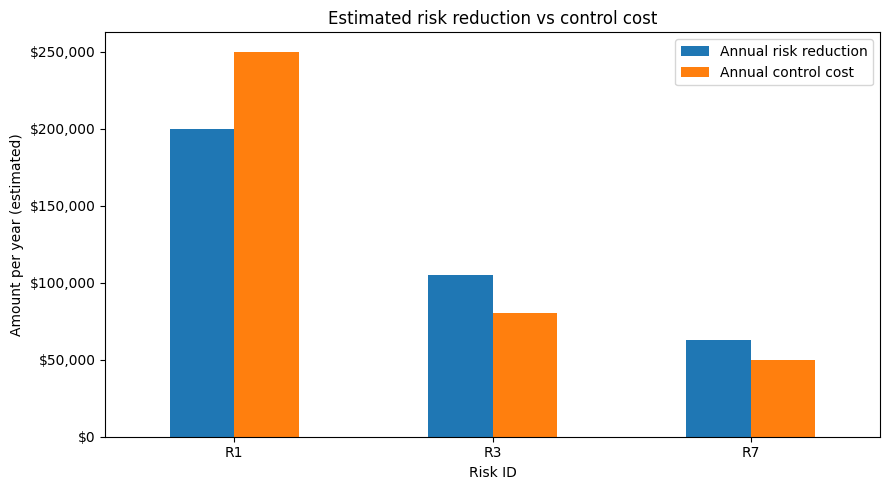

In [9]:
cost_comparison = risks_sorted.set_index('Risk_ID')[['Risk_Reduction', 'Control_Cost']]
cost_comparison.columns = ['Annual risk reduction', 'Annual control cost']

ax = cost_comparison.plot(kind='bar', figsize=(9, 5))
ax.yaxis.set_major_formatter(dollars)
ax.set_xlabel('Risk ID')
ax.set_ylabel('Amount per year (estimated)')
ax.set_title('Estimated risk reduction vs control cost')
plt.xticks(rotation=0)
finish('fig3_reduction_vs_cost')

## 8. Figure 4: Benefit-cost ratio

A ratio above 1 means the estimated annual risk reduction is greater than the estimated annual control cost. This is not a complete decision rule: legal, ethical, safety, and reputational reasons may justify a control whose ratio is below 1.

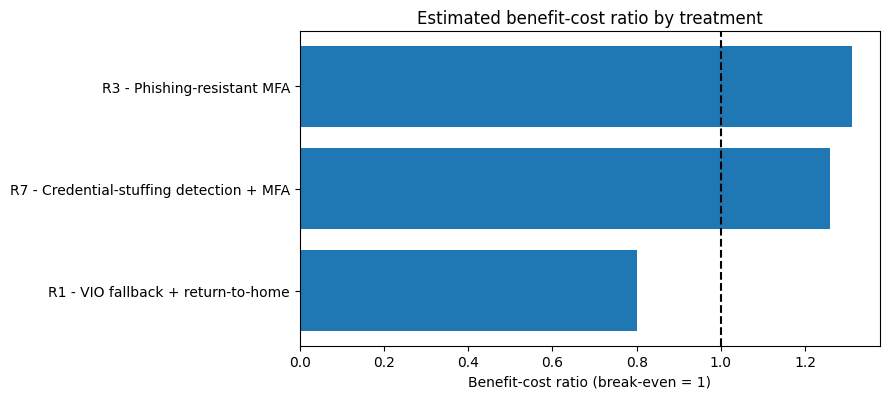

In [10]:
bcr_data = risks_sorted.dropna(subset=['Benefit_Cost_Ratio']).sort_values('Benefit_Cost_Ratio')

fig, ax = plt.subplots(figsize=(9, 0.7 * len(bcr_data) + 2))
ax.barh(bcr_data['Risk_ID'] + ' - ' + bcr_data['Control_Name'], bcr_data['Benefit_Cost_Ratio'])
ax.axvline(1, linestyle='--', color='black')
ax.set_xlabel('Benefit-cost ratio (break-even = 1)')
ax.set_title('Estimated benefit-cost ratio by treatment')
finish('fig4_benefit_cost_ratio')

## 9. Figure 5: Exposure bubble chart

Shows ARO (x-axis), SLE (y-axis) and ALE (bubble size) together. It separates risks that are rare but severe from those that are frequent but smaller, even when their ALE is the same.

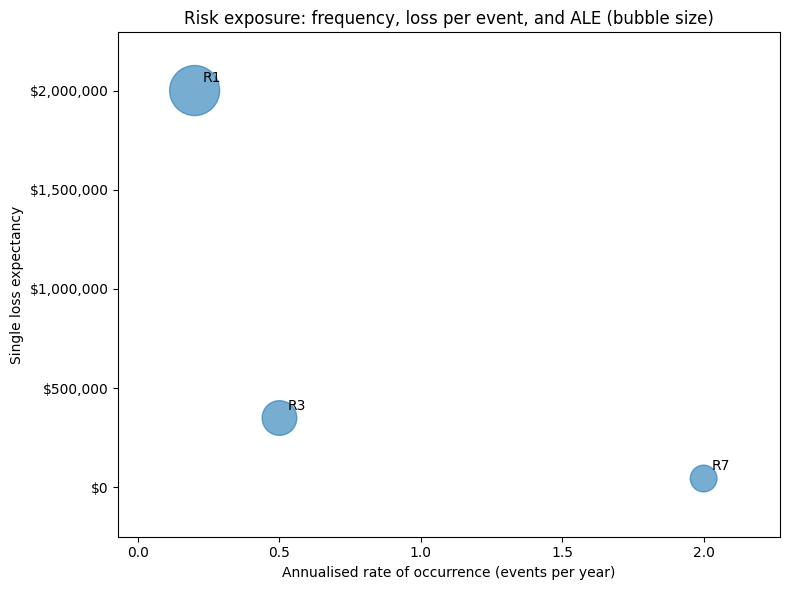

In [11]:
max_ale = risks['ALE'].max()
bubble_sizes = (risks['ALE'] / max_ale) * 1200 + 100 if max_ale > 0 else 300

fig, ax = plt.subplots(figsize=(8, 6))
ax.scatter(risks['ARO'], risks['SLE'], s=bubble_sizes, alpha=0.6)
for _, row in risks.iterrows():
    ax.annotate(row['Risk_ID'], (row['ARO'], row['SLE']), textcoords='offset points', xytext=(6, 6))
ax.yaxis.set_major_formatter(dollars)
ax.set_xlabel('Annualised rate of occurrence (events per year)')
ax.set_ylabel('Single loss expectancy')
ax.set_title('Risk exposure: frequency, loss per event, and ALE (bubble size)')
ax.margins(0.15)
finish('fig5_exposure_bubble')

## 10. Figure 6: Qualitative risk heatmap

Uses the `Likelihood_1_to_5` and `Impact_1_to_5` ratings and the same colour bands as the Practical 2 matrix. Risks that share a cell are listed together.

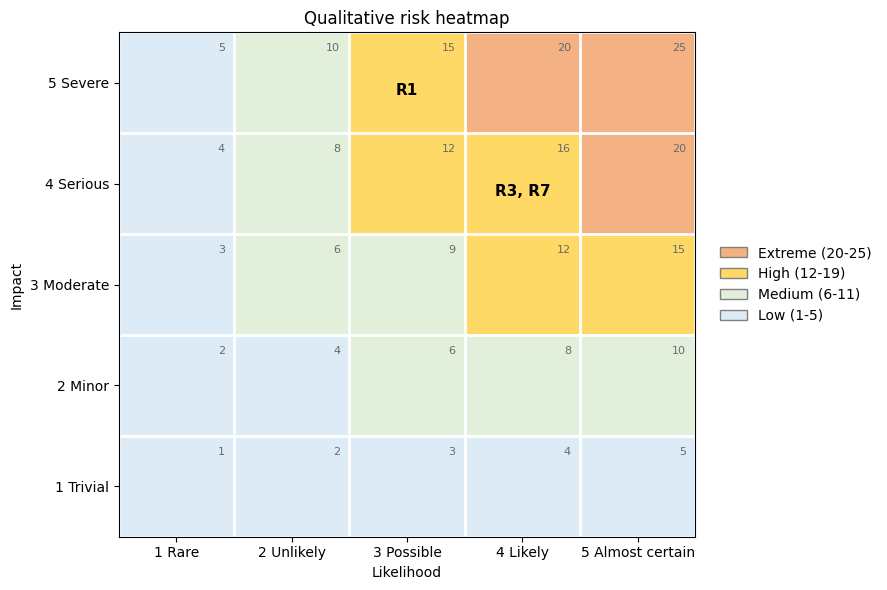

In [12]:
# Score grid with impact 5 on the top row
scores = np.array([[impact * likelihood for likelihood in range(1, 6)] for impact in range(5, 0, -1)])

band_colours = ['#DDEBF7', '#E2EFDA', '#FFD966', '#F4B183']   # Low, Medium, High, Extreme
cmap = ListedColormap(band_colours)
norm = BoundaryNorm([0, 5.5, 11.5, 19.5, 25.5], cmap.N)

fig, ax = plt.subplots(figsize=(9, 6))
ax.imshow(scores, cmap=cmap, norm=norm, aspect='auto')
ax.set_xticks(range(5))
ax.set_xticklabels(LIKELIHOOD_LABELS)
ax.set_yticks(range(5))
ax.set_yticklabels(IMPACT_LABELS[::-1])
ax.set_xlabel('Likelihood')
ax.set_ylabel('Impact')
ax.set_title('Qualitative risk heatmap')

# White grid lines between cells
ax.set_xticks(np.arange(-0.5, 5, 1), minor=True)
ax.set_yticks(np.arange(-0.5, 5, 1), minor=True)
ax.grid(which='minor', color='white', linewidth=2)
ax.tick_params(which='minor', length=0)

# Small score in the corner of each cell
for r in range(5):
    for col in range(5):
        ax.text(col + 0.42, r - 0.34, str(scores[r, col]), ha='right', va='center', fontsize=8, color='dimgray')

# Risk IDs, grouped so that risks sharing a cell do not overlap
def cell_label(ids):
    ids = list(ids)
    return '\n'.join(', '.join(ids[i:i + 2]) for i in range(0, len(ids), 2))   # two IDs per line

grouped = risks.groupby(['Likelihood_1_to_5', 'Impact_1_to_5'])['Risk_ID'].apply(cell_label)
for (likelihood, impact), label in grouped.items():
    crowded = label.count(',') + label.count('\n') >= 2
    ax.text(likelihood - 1, 5 - impact + 0.08, label, ha='center', va='center',
            fontweight='bold', fontsize=8.5 if crowded else 11)

legend_items = [Patch(facecolor=colour, edgecolor='gray', label=name) for colour, name in
                zip(band_colours[::-1], ['Extreme (20-25)', 'High (12-19)', 'Medium (6-11)', 'Low (1-5)'])]
ax.legend(handles=legend_items, loc='center left', bbox_to_anchor=(1.02, 0.5), frameon=False)
finish('fig6_heatmap')

## 11. Assumptions log

This log records the current quantitative assumptions used in the notebook. The figures are estimates for coursework analysis, not observed DJI internal data. Confidence indicates how strongly each estimate is supported at this stage.

| Risk ID | Value | Estimate | Source or reasoning | Confidence |
|---|---|---:|---|---|
| R3 | ARO | 0.50 | Assessment assumption informed by the Practical 2 Likelihood rating of 4 (Likely). This is a scenario mapping; no product-specific incident frequency is available in the supplied coursework materials. | Medium |
| R3 | SLE | $350,000 | Assessment assumption covering incident response/recovery, service disruption, customer notification/legal work, and plausible business loss from a privileged-account compromise. | Low |
| R3 | Control cost | $80,000/year | Estimated annual TCO for phishing-resistant MFA, identity administration, rollout/training, monitoring, and maintenance. | Medium |
| R3 | Likelihood reduction | 60% | Assessment assumption that phishing-resistant MFA materially reduces successful privileged credential compromise. The treatment is designed to reduce likelihood. | Medium |
| R7 | ARO | 2.00 | Assessment assumption informed by the Practical 2 Likelihood rating of 4 (Likely) and the persistent nature of credential-stuffing attacks. No DJI-specific frequency is available in the supplied materials. | Medium |
| R7 | SLE | $45,000 | Assessment assumption covering response/recovery, investigation, customer remediation/support, and operational disruption for a material account-takeover event. | Low |
| R7 | Control cost | $50,000/year | Estimated annual TCO for credential-stuffing detection, monitoring, MFA support, and operational maintenance. | Medium |
| R7 | Likelihood reduction | 70% | Assessment assumption for combined credential-stuffing detection and MFA. The treatment is designed primarily to reduce likelihood. | Medium |
| R1 | ARO | 0.20 | Assessment assumption informed by the Practical 2 Likelihood rating of 3 (Possible). No DJI-specific GPS-spoofing frequency is provided in the supplied materials. | Low |
| R1 | SLE | $2,000,000 | Assessment assumption representing a severe single-event case including emergency response, operational disruption, asset loss, legal/claims exposure, and major reputational consequences. | Low |
| R1 | Control cost | $250,000/year | Estimated annual TCO for engineering, testing, deployment, maintenance, and operational support for VIO fallback and signal-anomaly handling. | Low |
| R1 | Impact reduction | 50% | Assessment assumption that VIO fallback and return-to-home can materially reduce consequences when GPS signals are unreliable. The treatment is designed to reduce impact. | Low |

The next revision of this log should replace the weakest assumptions with stronger documentary, system, process, or expert evidence as required by Practical 4.

## 12. Current quantitative interpretation

The current assumptions are designed to illustrate three different exposure patterns while remaining aligned with the Practical 2 qualitative ratings:

- R1 is a low-frequency, very high-loss safety scenario and is expected to have the highest ALE.
- R3 represents privileged account compromise in the DeliveryHub / DJI unified-account scope. Its numerical inputs remain scenario assumptions rather than product-specific measured data.
- R7 is more frequent but has a lower single-event loss, illustrating how frequent smaller events can accumulate substantial annual exposure.

The treatment calculations should be interpreted as decision-support estimates, not precise forecasts. Practical 4 will test how robust these conclusions remain when the weakest assumptions are replaced with ranges.

## 13. Sensitivity analysis: Low, Most Likely, and High scenarios

This section incorporates the completed Practical 4 scenario ranges. It varies ARO and SLE for each selected risk while holding annual control costs and treatment-effect assumptions constant. This isolates how uncertainty in frequency and loss severity affects ALE, residual ALE, risk reduction, and BCR. These are scenario bounds, **not** confidence intervals or probability distributions.

In [13]:
sensitivity_inputs = pd.DataFrame([
    {'Risk_ID': 'R1', 'Scenario': 'Low', 'ARO': 0.10, 'SLE': 1_000_000},
    {'Risk_ID': 'R1', 'Scenario': 'Most Likely', 'ARO': 0.20, 'SLE': 2_000_000},
    {'Risk_ID': 'R1', 'Scenario': 'High', 'ARO': 0.30, 'SLE': 3_500_000},
    {'Risk_ID': 'R3', 'Scenario': 'Low', 'ARO': 0.25, 'SLE': 200_000},
    {'Risk_ID': 'R3', 'Scenario': 'Most Likely', 'ARO': 0.50, 'SLE': 350_000},
    {'Risk_ID': 'R3', 'Scenario': 'High', 'ARO': 0.75, 'SLE': 600_000},
    {'Risk_ID': 'R7', 'Scenario': 'Low', 'ARO': 1.00, 'SLE': 30_000},
    {'Risk_ID': 'R7', 'Scenario': 'Most Likely', 'ARO': 2.00, 'SLE': 45_000},
    {'Risk_ID': 'R7', 'Scenario': 'High', 'ARO': 3.00, 'SLE': 70_000},
])

control_lookup = risk_inputs.set_index('Risk_ID')[['Control_Cost', 'Likelihood_Reduction_pct', 'Impact_Reduction_pct']]
sensitivity = sensitivity_inputs.join(control_lookup, on='Risk_ID')
sensitivity['ALE'] = sensitivity['ARO'] * sensitivity['SLE']
sensitivity['Residual_ARO'] = sensitivity['ARO'] * (1 - sensitivity['Likelihood_Reduction_pct'] / 100)
sensitivity['Residual_SLE'] = sensitivity['SLE'] * (1 - sensitivity['Impact_Reduction_pct'] / 100)
sensitivity['Residual_ALE'] = sensitivity['Residual_ARO'] * sensitivity['Residual_SLE']
sensitivity['Risk_Reduction'] = sensitivity['ALE'] - sensitivity['Residual_ALE']
sensitivity['Net_Benefit'] = sensitivity['Risk_Reduction'] - sensitivity['Control_Cost']
sensitivity['BCR'] = np.where(sensitivity['Control_Cost'] > 0, sensitivity['Risk_Reduction'] / sensitivity['Control_Cost'], np.nan)

sensitivity

,Risk_ID,Scenario,ARO,SLE,Control_Cost,Likelihood_Reduction_pct,Impact_Reduction_pct,ALE,Residual_ARO,Residual_SLE,Residual_ALE,Risk_Reduction,Net_Benefit,BCR
0,R1,Low,0.10,1000000,250000,0,50,"100,000.00",0.10,"500,000.00","50,000.00","50,000.00","-200,000.00",0.20
1,R1,Most Likely,0.20,2000000,250000,0,50,"400,000.00",0.20,"1,000,000.00","200,000.00","200,000.00","-50,000.00",0.80
2,R1,High,0.30,3500000,250000,0,50,"1,050,000.00",0.30,"1,750,000.00","525,000.00","525,000.00","275,000.00",2.10
3,R3,Low,0.25,200000,80000,60,0,"50,000.00",0.10,"200,000.00","20,000.00","30,000.00","-50,000.00",0.38
4,R3,Most Likely,0.50,350000,80000,60,0,"175,000.00",0.20,"350,000.00","70,000.00","105,000.00","25,000.00",1.31
5,R3,High,0.75,600000,80000,60,0,"450,000.00",0.30,"600,000.00","180,000.00","270,000.00","190,000.00",3.38
6,R7,Low,1.00,30000,50000,70,0,"30,000.00",0.30,"30,000.00","9,000.00","21,000.00","-29,000.00",0.42
7,R7,Most Likely,2.00,45000,50000,70,0,"90,000.00",0.60,"45,000.00","27,000.00","63,000.00","13,000.00",1.26
8,R7,High,3.00,70000,50000,70,0,"210,000.00",0.90,"70,000.00","63,000.00","147,000.00","97,000.00",2.94


### 13.1 Sensitivity summary

The summary below reports ALE and BCR for each scenario. The comparison is only as reliable as the scenario assumptions; control costs and treatment effectiveness are deliberately held fixed in this sensitivity test.

In [14]:
sensitivity_summary = sensitivity.pivot(index='Risk_ID', columns='Scenario', values='ALE').reindex(columns=['Low', 'Most Likely', 'High'])
sensitivity_summary['BCR range (Low / Most Likely / High)'] = sensitivity.groupby('Risk_ID').apply(lambda g: ' / '.join(f"{v:.3g}" for v in g.set_index('Scenario').loc[['Low', 'Most Likely', 'High'], 'BCR']), include_groups=False)
sensitivity_summary = sensitivity_summary.reset_index()
sensitivity_summary

Scenario,Risk_ID,Low,Most Likely,High,BCR range (Low / Most Likely / High)
0,R1,"100,000.00","400,000.00","1,050,000.00",0.2 / 0.8 / 2.1
1,R3,"50,000.00","175,000.00","450,000.00",0.375 / 1.31 / 3.38
2,R7,"30,000.00","90,000.00","210,000.00",0.42 / 1.26 / 2.94


In [15]:
if SAVE_FIGURES:
    sensitivity.to_csv('sensitivity_risk_summary.csv', index=False)
    sensitivity_summary.to_csv('sensitivity_summary.csv', index=False)

# Check whether the ALE ranking changes across the three scenarios.
for scenario in ['Low', 'Most Likely', 'High']:
    ranked = sensitivity[sensitivity['Scenario'] == scenario].sort_values('ALE', ascending=False)['Risk_ID'].tolist()
    print(f'{scenario} ALE ranking: ' + ' > '.join(ranked))

Low ALE ranking: R1 > R3 > R7
Most Likely ALE ranking: R1 > R3 > R7
High ALE ranking: R1 > R3 > R7


## 14. Interpretation and limitations

- The central case produces ALE values of **$400,000 for R1**, **$175,000 for R3**, and **$90,000 for R7**.
- Under the central assumptions, R3 and R7 have positive net benefits and BCRs above 1. R1 has BCR 0.80; its treatment decision should not be based on BCR alone because the scenario is safety-critical.
- Across the Low, Most Likely, and High cases, the ALE ranking remains R1 > R3 > R7.
- Qualitative risk scores are ordinal ratings; ALE is a monetary annualised estimate. They should not be treated as interchangeable measures.
- ARO, SLE, control costs, and control-effectiveness percentages are assumptions. Validate them against operational data, supplier evidence, engineering testing, and cost information when available.
- R3's DeliveryHub / DJI unified-account wording defines the assessment scope; the retained numerical model does not establish a verified DeliveryHub-specific incident rate or control gap.
- The main report uses Figure 2 (current vs residual ALE) and Figure 4 (benefit-cost ratio with the break-even line), with captions and interpretation; both are embedded in the report at 200 dpi from this notebook's own output. All report figures must be regenerated from this final notebook.

In [16]:
# Final reproducibility checks: key expected central-case outputs.
expected = {'R1': (400000, 200000, 200000, -50000, 0.80),
            'R3': (175000, 70000, 105000, 25000, 1.3125),
            'R7': (90000, 27000, 63000, 13000, 1.26)}
for risk_id, values in expected.items():
    row = risks.set_index('Risk_ID').loc[risk_id]
    actual = (row['ALE'], row['Residual_ALE'], row['Risk_Reduction'], row['Net_Benefit'], row['Benefit_Cost_Ratio'])
    assert np.allclose(actual, values, rtol=1e-9, atol=1e-6), f'{risk_id}: expected {values}, got {actual}'
print('Final validation passed: central-case metrics match the verified assessment values.')

Final validation passed: central-case metrics match the verified assessment values.
